In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from pathlib import Path

ROOT = Path.cwd().parent            # project folder (the notebook lives in notebooks/)
RAW_PATH = ROOT / "data" / "raw" / "swiggy.csv"
PROCESSED = ROOT / "data" / "processed"
assert RAW_PATH.exists(), f"Put swiggy.csv in {RAW_PATH.parent}"

In [2]:
def haversine(lat1, lon1, lat2, lon2):
    R = 6371
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = (np.sin((lat2 - lat1) / 2) ** 2
         + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2)
    return 2 * R * np.arcsin(np.sqrt(a))


def clean_data(raw_df):
    df = raw_df.copy()

    # 1. fake "NaN " text -> real blanks
    df = df.replace(r'^\s*NaN\s*$', np.nan, regex=True)

    # 2. city code from delivery person ID, then drop ID columns
    df['city_code'] = df['Delivery_person_ID'].str.strip().str.lower().str[:4]
    df = df.drop(columns=['ID', 'Delivery_person_ID'])

    # 3. rename columns
    df = df.rename(columns={
        'Delivery_person_Age': 'age',
        'Delivery_person_Ratings': 'rating',
        'Restaurant_latitude': 'restaurant_latitude',
        'Restaurant_longitude': 'restaurant_longitude',
        'Delivery_location_latitude': 'location_latitude',
        'Delivery_location_longitude': 'location_longitude',
        'Order_Date': 'date',
        'Time_Orderd': 'time_of_order',
        'Time_Order_picked': 'pickup_time',
        'Weatherconditions': 'weather',
        'Road_traffic_density': 'traffic',
        'Vehicle_condition': 'vehicle_condition',
        'Type_of_order': 'order_type',
        'Type_of_vehicle': 'vehicle_type',
        'multiple_deliveries': 'no_of_deliveries',
        'Festival': 'festival',
        'City': 'city',
        'Time_taken(min)': 'total_time_taken',
    })

    # 4. text columns: strip spaces + lowercase (blanks stay blank)
    for col in ['traffic', 'weather', 'festival', 'city', 'order_type', 'vehicle_type']:
        df[col] = df[col].str.strip().str.lower()
    df['weather'] = df['weather'].str.replace('conditions ', '', regex=False)
    df['weather'] = df['weather'].mask(df['weather'] == 'nan')

    # 5. number columns
    for col in ['age', 'rating', 'no_of_deliveries']:
        df[col] = pd.to_numeric(df[col], errors='coerce')
    df['total_time_taken'] = pd.to_numeric(
        df['total_time_taken'].astype(str).str.extract(r'(\d+)')[0], errors='coerce')

    # 6. date
    df['date'] = pd.to_datetime(df['date'], format='%d-%m-%Y', errors='coerce')

    # 7. impossible values -> blank (blank ages are kept)
    df = df[df['age'].isna() | df['age'].between(20, 39)].copy()
    df.loc[~df['rating'].between(1, 5), 'rating'] = np.nan
    df.loc[~df['vehicle_condition'].between(0, 2), 'vehicle_condition'] = np.nan
    df.loc[df['vehicle_type'] == 'bicycle', 'vehicle_type'] = np.nan

    # 8. time features
    t_order = pd.to_datetime(df['time_of_order'].str.strip(), format='%H:%M:%S', errors='coerce')
    t_pick = pd.to_datetime(df['pickup_time'].str.strip(), format='%H:%M:%S', errors='coerce')
    df['order_hour'] = t_order.dt.hour
    df['pickup_time(min)'] = ((t_pick - t_order).dt.total_seconds() / 60) % 1440

    h = df['order_hour']
    df['time_of_day'] = np.select(
        [h.between(5, 11), h.between(12, 16), h.between(17, 20), (h >= 21) | (h < 5)],
        ['morning', 'afternoon', 'evening', 'night'],
        default='unknown')
    df.loc[h.isna(), 'time_of_day'] = np.nan

    # 9. date features
    df['day_name'] = df['date'].dt.day_name().str.lower()
    df['month_name'] = df['date'].dt.month_name().str.lower()
    df['is_weekend'] = (df['date'].dt.dayofweek >= 5).astype('boolean').mask(df['date'].isna())

    # 10. coordinates: positive, outside India -> blank
    ranges = {
        'restaurant_latitude': (8, 37), 'location_latitude': (8, 37),
        'restaurant_longitude': (68, 98), 'location_longitude': (68, 98),
    }
    for col, (low, high) in ranges.items():
        df[col] = df[col].abs()
        df.loc[~df[col].between(low, high), col] = np.nan

    # 11. distance (blank where a coordinate is blank)
    df['distance_km'] = haversine(
        df['restaurant_latitude'], df['restaurant_longitude'],
        df['location_latitude'], df['location_longitude']).round(2)

    return df.reset_index(drop=True)

In [3]:
raw = pd.read_csv(RAW_PATH)
df = clean_data(raw)
df.to_csv(PROCESSED / "swiggy_cleaned.csv", index=False)

print(df.shape)            # expect (45502, 26)
print(df.isna().sum())

(45502, 26)
age                     1854
rating                  1908
restaurant_latitude     3630
restaurant_longitude    3630
location_latitude       3630
location_longitude      3630
date                       0
time_of_order           1640
pickup_time                0
weather                  525
traffic                  510
vehicle_condition        429
order_type                 0
vehicle_type              53
no_of_deliveries         993
festival                 228
city                    1198
total_time_taken           0
city_code                  0
order_hour              1640
pickup_time(min)        1640
time_of_day             1640
day_name                   0
month_name                 0
is_weekend                 0
distance_km             3630
dtype: int64


In [4]:
print("Duplicates:", df.duplicated().sum())
display(df.describe().T)
display(df.describe(include='str').T)

Duplicates: 0


,count,mean,min,25%,50%,75%,max,std
age,43648.0,29.555008,20.0,25.0,30.0,35.0,39.0,5.761482
rating,43594.0,4.635287,2.5,4.5,4.7,4.9,5.0,0.313827
restaurant_latitude,41872.0,18.913696,9.957144,12.986047,19.065838,22.751234,30.914057,5.467265
restaurant_longitude,41872.0,76.921664,72.768726,73.897902,76.618203,78.368855,88.433452,3.503107
location_latitude,41872.0,18.977356,9.967144,13.065996,19.124049,22.82004,31.054057,5.469056
location_longitude,41872.0,76.985325,72.778726,73.940327,76.66262,78.405467,88.563452,3.50326
date,45502,2022-03-13 16:34:49.332336,2022-02-11 00:00:00,2022-03-04 00:00:00,2022-03-15 00:00:00,2022-03-27 00:00:00,2022-04-06 00:00:00,NaN
vehicle_condition,45073.0,1.000555,0.0,0.0,1.0,2.0,2.0,0.816428
no_of_deliveries,44509.0,0.744928,0.0,0.0,1.0,1.0,3.0,0.572488
total_time_taken,45502.0,26.297591,10.0,19.0,26.0,32.0,54.0,9.386419


,count,unique,top,freq
time_of_order,43862,176,21:55:00,461
pickup_time,45502,193,21:30:00,496
weather,44977,6,fog,7654
traffic,44992,4,low,15477
order_type,45502,4,snack,11512
vehicle_type,45449,3,motorcycle,26427
festival,45274,2,no,44380
city,44304,3,metropolitian,34029
city_code,45502,22,japr,3439
time_of_day,43862,4,evening,17892


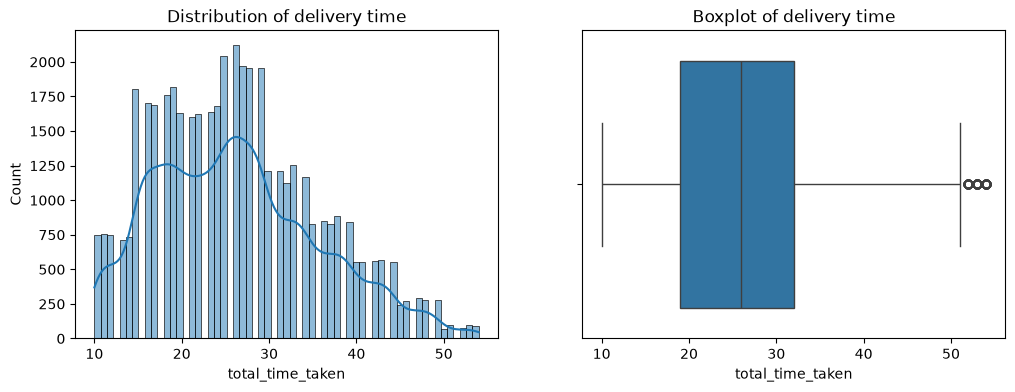

count    45502.000000
mean        26.297591
std          9.386419
min         10.000000
25%         19.000000
50%         26.000000
75%         32.000000
max         54.000000
Name: total_time_taken, dtype: float64
Skew: 0.485582469348261 | Kurtosis: -0.3116377537837778


In [5]:
y = df['total_time_taken']
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(y, kde=True, ax=ax[0]); ax[0].set_title('Distribution of delivery time')
sns.boxplot(x=y, ax=ax[1]); ax[1].set_title('Boxplot of delivery time')
plt.show()
print(y.describe())
print("Skew:", y.skew(), "| Kurtosis:", y.kurt())

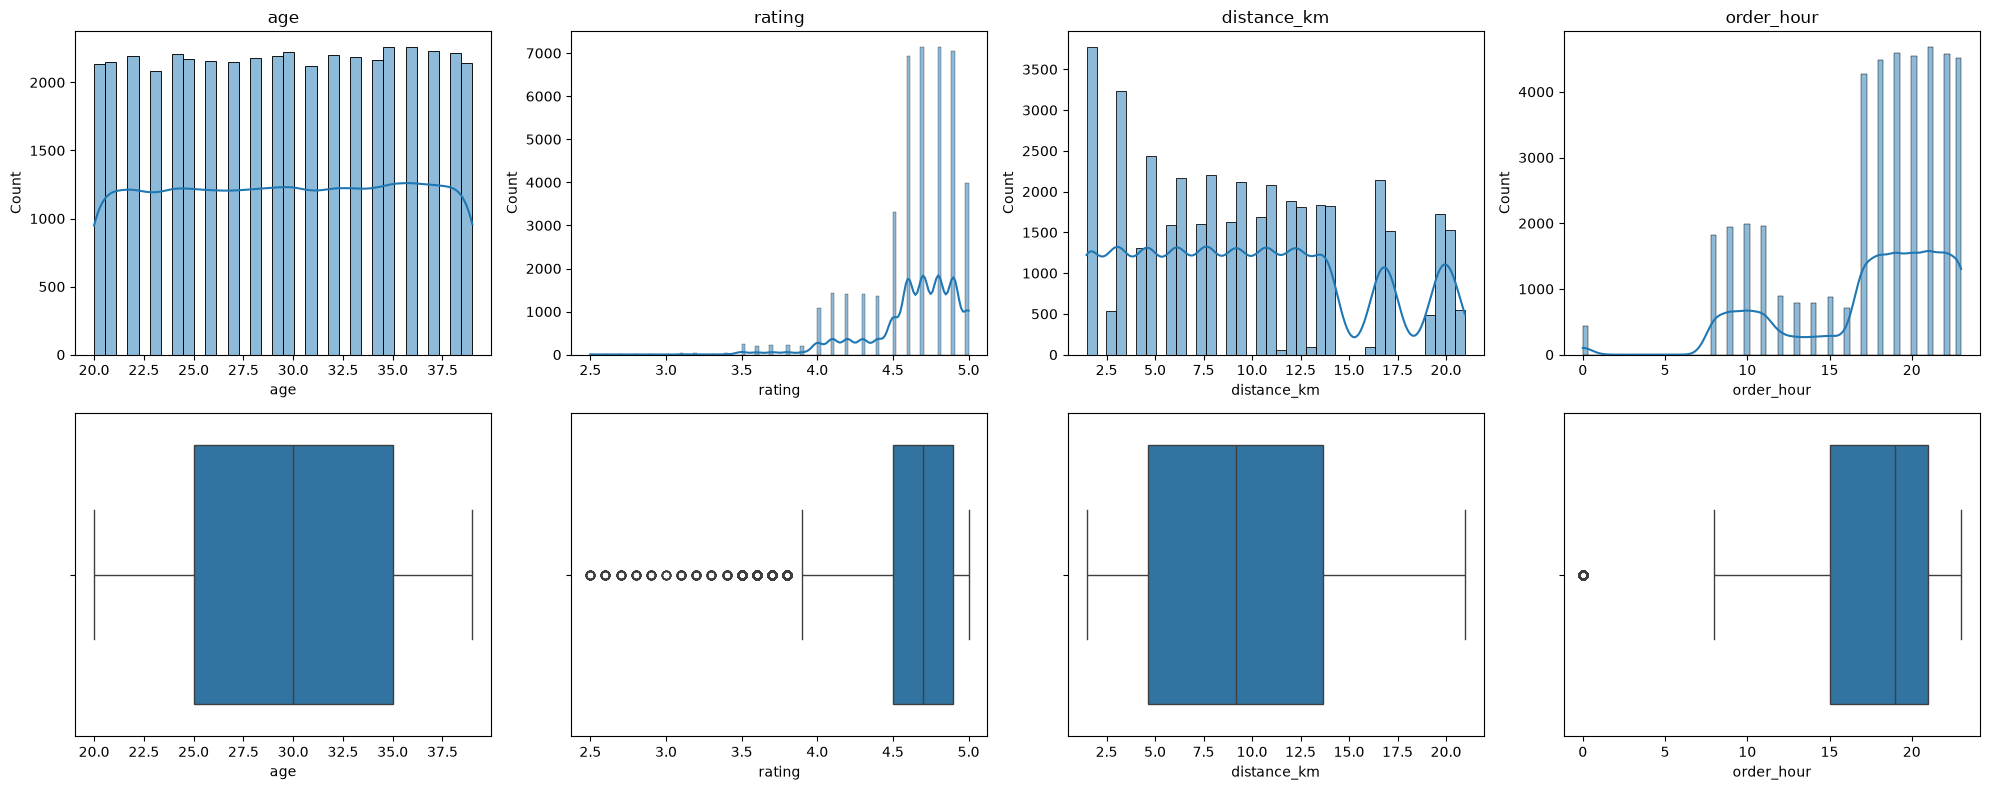

              mean  median   std    min    max  skew  kurt
age          29.56   30.00  5.76  20.00  39.00 -0.01 -1.21
rating        4.64    4.70  0.31   2.50   5.00 -1.79  5.14
distance_km   9.72    9.19  5.60   1.47  20.97  0.32 -0.91
order_hour   17.42   19.00  4.82   0.00  23.00 -1.02  0.46
age: 0 outliers (0.00%), range 10.00 to 50.00
rating: 1132 outliers (2.60%), range 3.90 to 5.50
distance_km: 0 outliers (0.00%), range -8.87 to 27.21
order_hour: 430 outliers (0.98%), range 6.00 to 30.00
total_time_taken: 270 outliers (0.59%), range -0.50 to 51.50


In [6]:
num_cols = ['age', 'rating', 'distance_km', 'order_hour']

fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for i, col in enumerate(num_cols):
    sns.histplot(df[col], kde=True, ax=axes[0, i]); axes[0, i].set_title(col)
    sns.boxplot(x=df[col], ax=axes[1, i])
plt.tight_layout(); plt.show()

print(df[num_cols].agg(['mean', 'median', 'std', 'min', 'max', 'skew', 'kurt']).T.round(2))

for col in num_cols + ['total_time_taken']:       # outlier counts (IQR), nothing is removed
    s = df[col].dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n = ((s < low) | (s > high)).sum()
    print(f"{col}: {n} outliers ({n / len(s) * 100:.2f}%), range {low:.2f} to {high:.2f}")

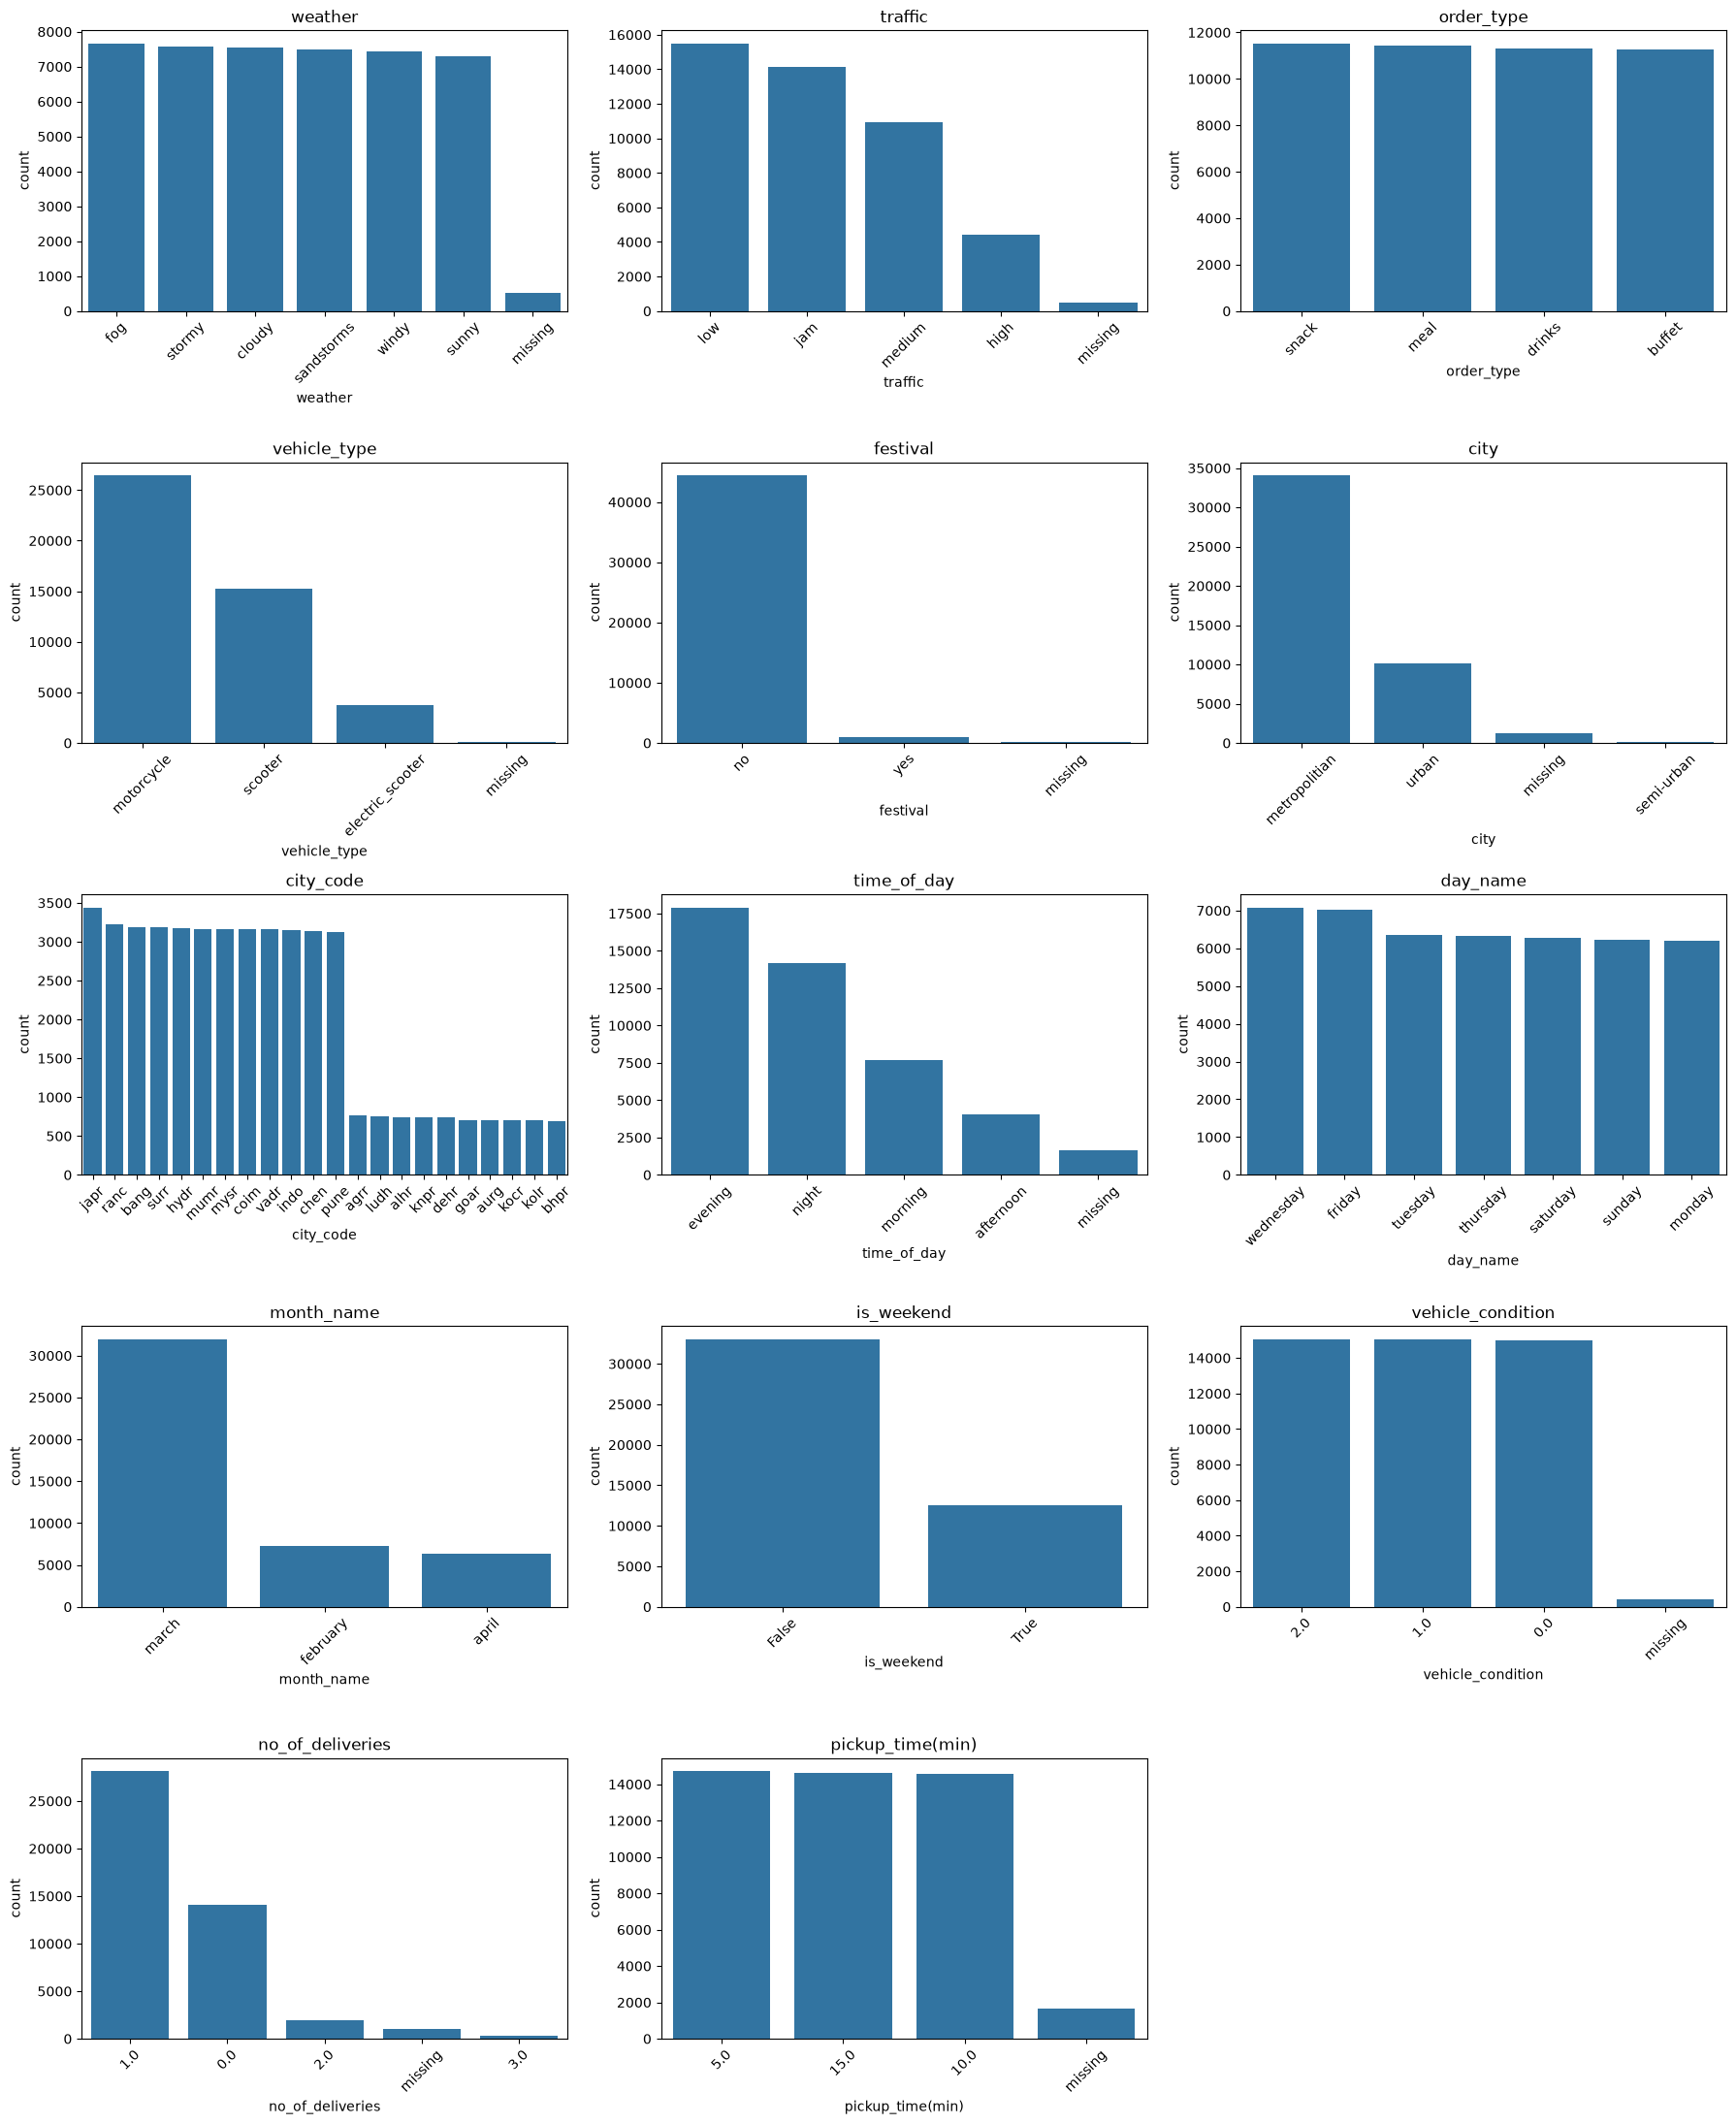

weather
fog           16.8
stormy        16.7
cloudy        16.6
sandstorms    16.5
windy         16.3
sunny         16.0
NaN            1.2
Name: proportion, dtype: float64 

traffic
low       34.0
jam       31.1
medium    24.1
high       9.7
NaN        1.1
Name: proportion, dtype: float64 

order_type
snack     25.3
meal      25.1
drinks    24.8
buffet    24.7
Name: proportion, dtype: float64 

vehicle_type
motorcycle          58.1
scooter             33.5
electric_scooter     8.3
NaN                  0.1
Name: proportion, dtype: float64 

festival
no     97.5
yes     2.0
NaN     0.5
Name: proportion, dtype: float64 

city
metropolitian    74.8
urban            22.2
NaN               2.6
semi-urban        0.4
Name: proportion, dtype: float64 

city_code
japr    7.6
ranc    7.1
bang    7.0
surr    7.0
hydr    7.0
mumr    7.0
mysr    7.0
coim    6.9
vadr    6.9
indo    6.9
chen    6.9
pune    6.9
agrr    1.7
ludh    1.7
alhr    1.6
knpr    1.6
dehr    1.6
goar    1.6
aurg    1.5
kocr  

In [7]:
def with_missing(s):
    return s.astype(object).where(s.notna(), 'missing').astype(str)

cat_cols_eda = ['weather', 'traffic', 'order_type', 'vehicle_type', 'festival', 'city',
                'city_code', 'time_of_day', 'day_name', 'month_name', 'is_weekend',
                'vehicle_condition', 'no_of_deliveries', 'pickup_time(min)']

fig, axes = plt.subplots(5, 3, figsize=(18, 22))
axes = axes.flatten()
for i, col in enumerate(cat_cols_eda):
    s = with_missing(df[col])
    sns.countplot(x=s, order=s.value_counts().index, ax=axes[i])
    axes[i].set_title(col); axes[i].tick_params(axis='x', rotation=45)
for j in range(len(cat_cols_eda), len(axes)):
    axes[j].axis('off')
plt.tight_layout(); plt.show()

for col in cat_cols_eda:
    print(df[col].value_counts(normalize=True, dropna=False).round(3) * 100, "\n")

total_time_taken    1.000
distance_km         0.321
age                 0.304
order_hour          0.184
rating             -0.361
Name: total_time_taken, dtype: float64
              age  rating  distance_km  order_hour
age          1.00   -0.12        -0.00       -0.00
rating      -0.12    1.00        -0.11       -0.06
distance_km -0.00   -0.11         1.00        0.58
order_hour  -0.00   -0.06         0.58        1.00


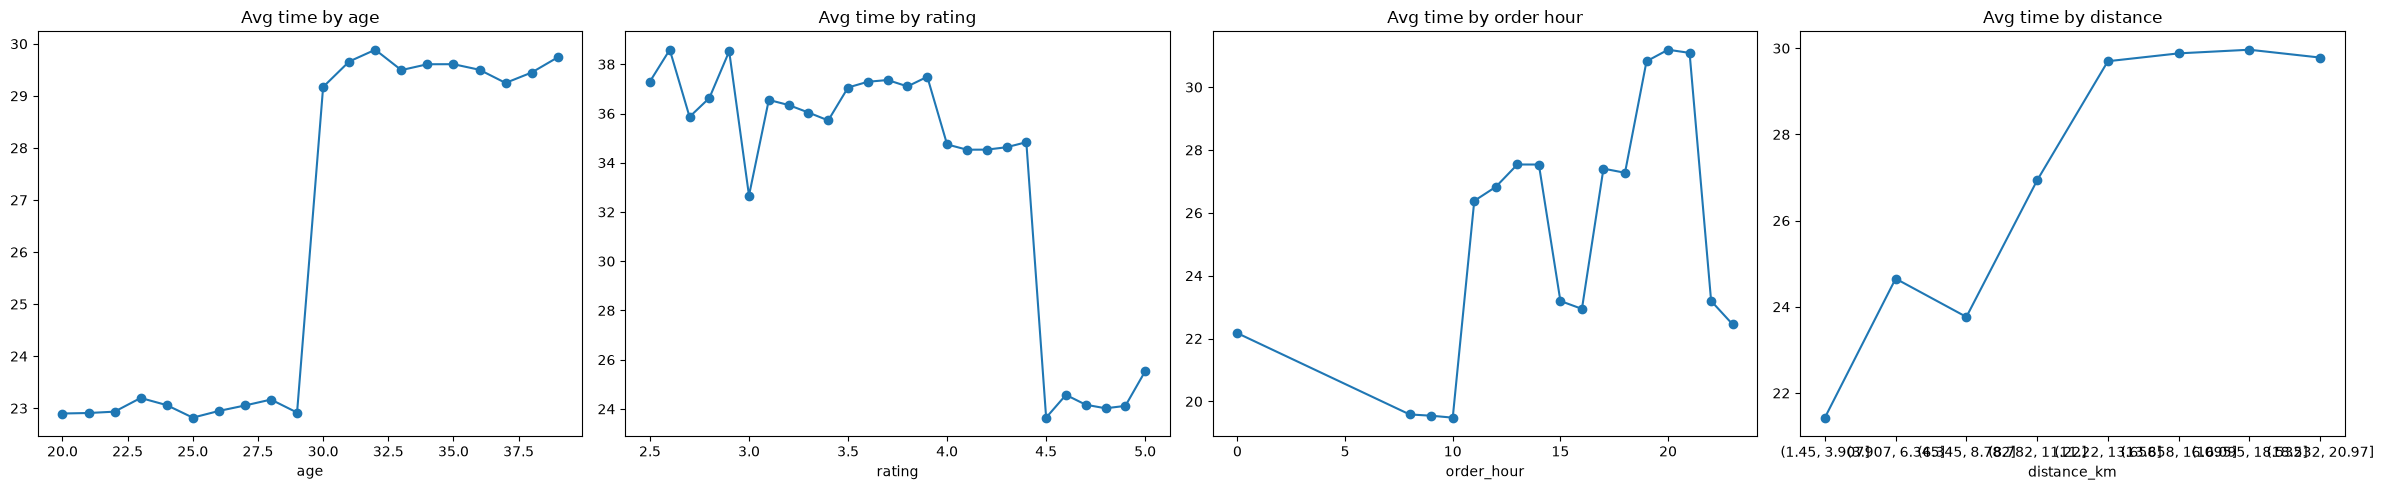

In [8]:
corr_cols = ['age', 'rating', 'distance_km', 'order_hour', 'total_time_taken']
print(df[corr_cols].corr()['total_time_taken'].sort_values(ascending=False).round(3))
print(df[['age', 'rating', 'distance_km', 'order_hour']].corr().round(2))

fig, axes = plt.subplots(1, 4, figsize=(24, 5))
df.groupby('age')['total_time_taken'].mean().plot(ax=axes[0], marker='o', title='Avg time by age')
df.groupby('rating')['total_time_taken'].mean().plot(ax=axes[1], marker='o', title='Avg time by rating')
df.groupby('order_hour')['total_time_taken'].mean().plot(ax=axes[2], marker='o', title='Avg time by order hour')
df.groupby(pd.cut(df['distance_km'], bins=8), observed=True)['total_time_taken'].mean().plot(
    ax=axes[3], marker='o', title='Avg time by distance')
plt.tight_layout(); plt.show()

            mean  median  count
weather                        
sunny       21.9    20.0   7284
sandstorms  25.9    26.0   7495
stormy      25.9    26.0   7586
windy       26.1    26.0   7422
missing     26.8    26.0    525
cloudy      28.9    28.0   7536
fog         28.9    28.0   7654 

         mean  median  count
traffic                     
low      21.3    20.0  15477
medium   26.7    27.0  10947
missing  26.9    26.0    510
high     27.2    27.0   4425
jam      31.2    31.0  14143 

            mean  median  count
order_type                     
drinks      26.2    25.0  11294
buffet      26.3    26.0  11261
snack       26.3    26.0  11512
meal        26.4    26.0  11435 

                  mean  median  count
vehicle_type                         
electric_scooter  24.5    24.0   3778
scooter           24.5    24.0  15244
missing           26.7    28.0     53
motorcycle        27.6    26.0  26427 

          mean  median  count
festival                     
missing   11.2    11.

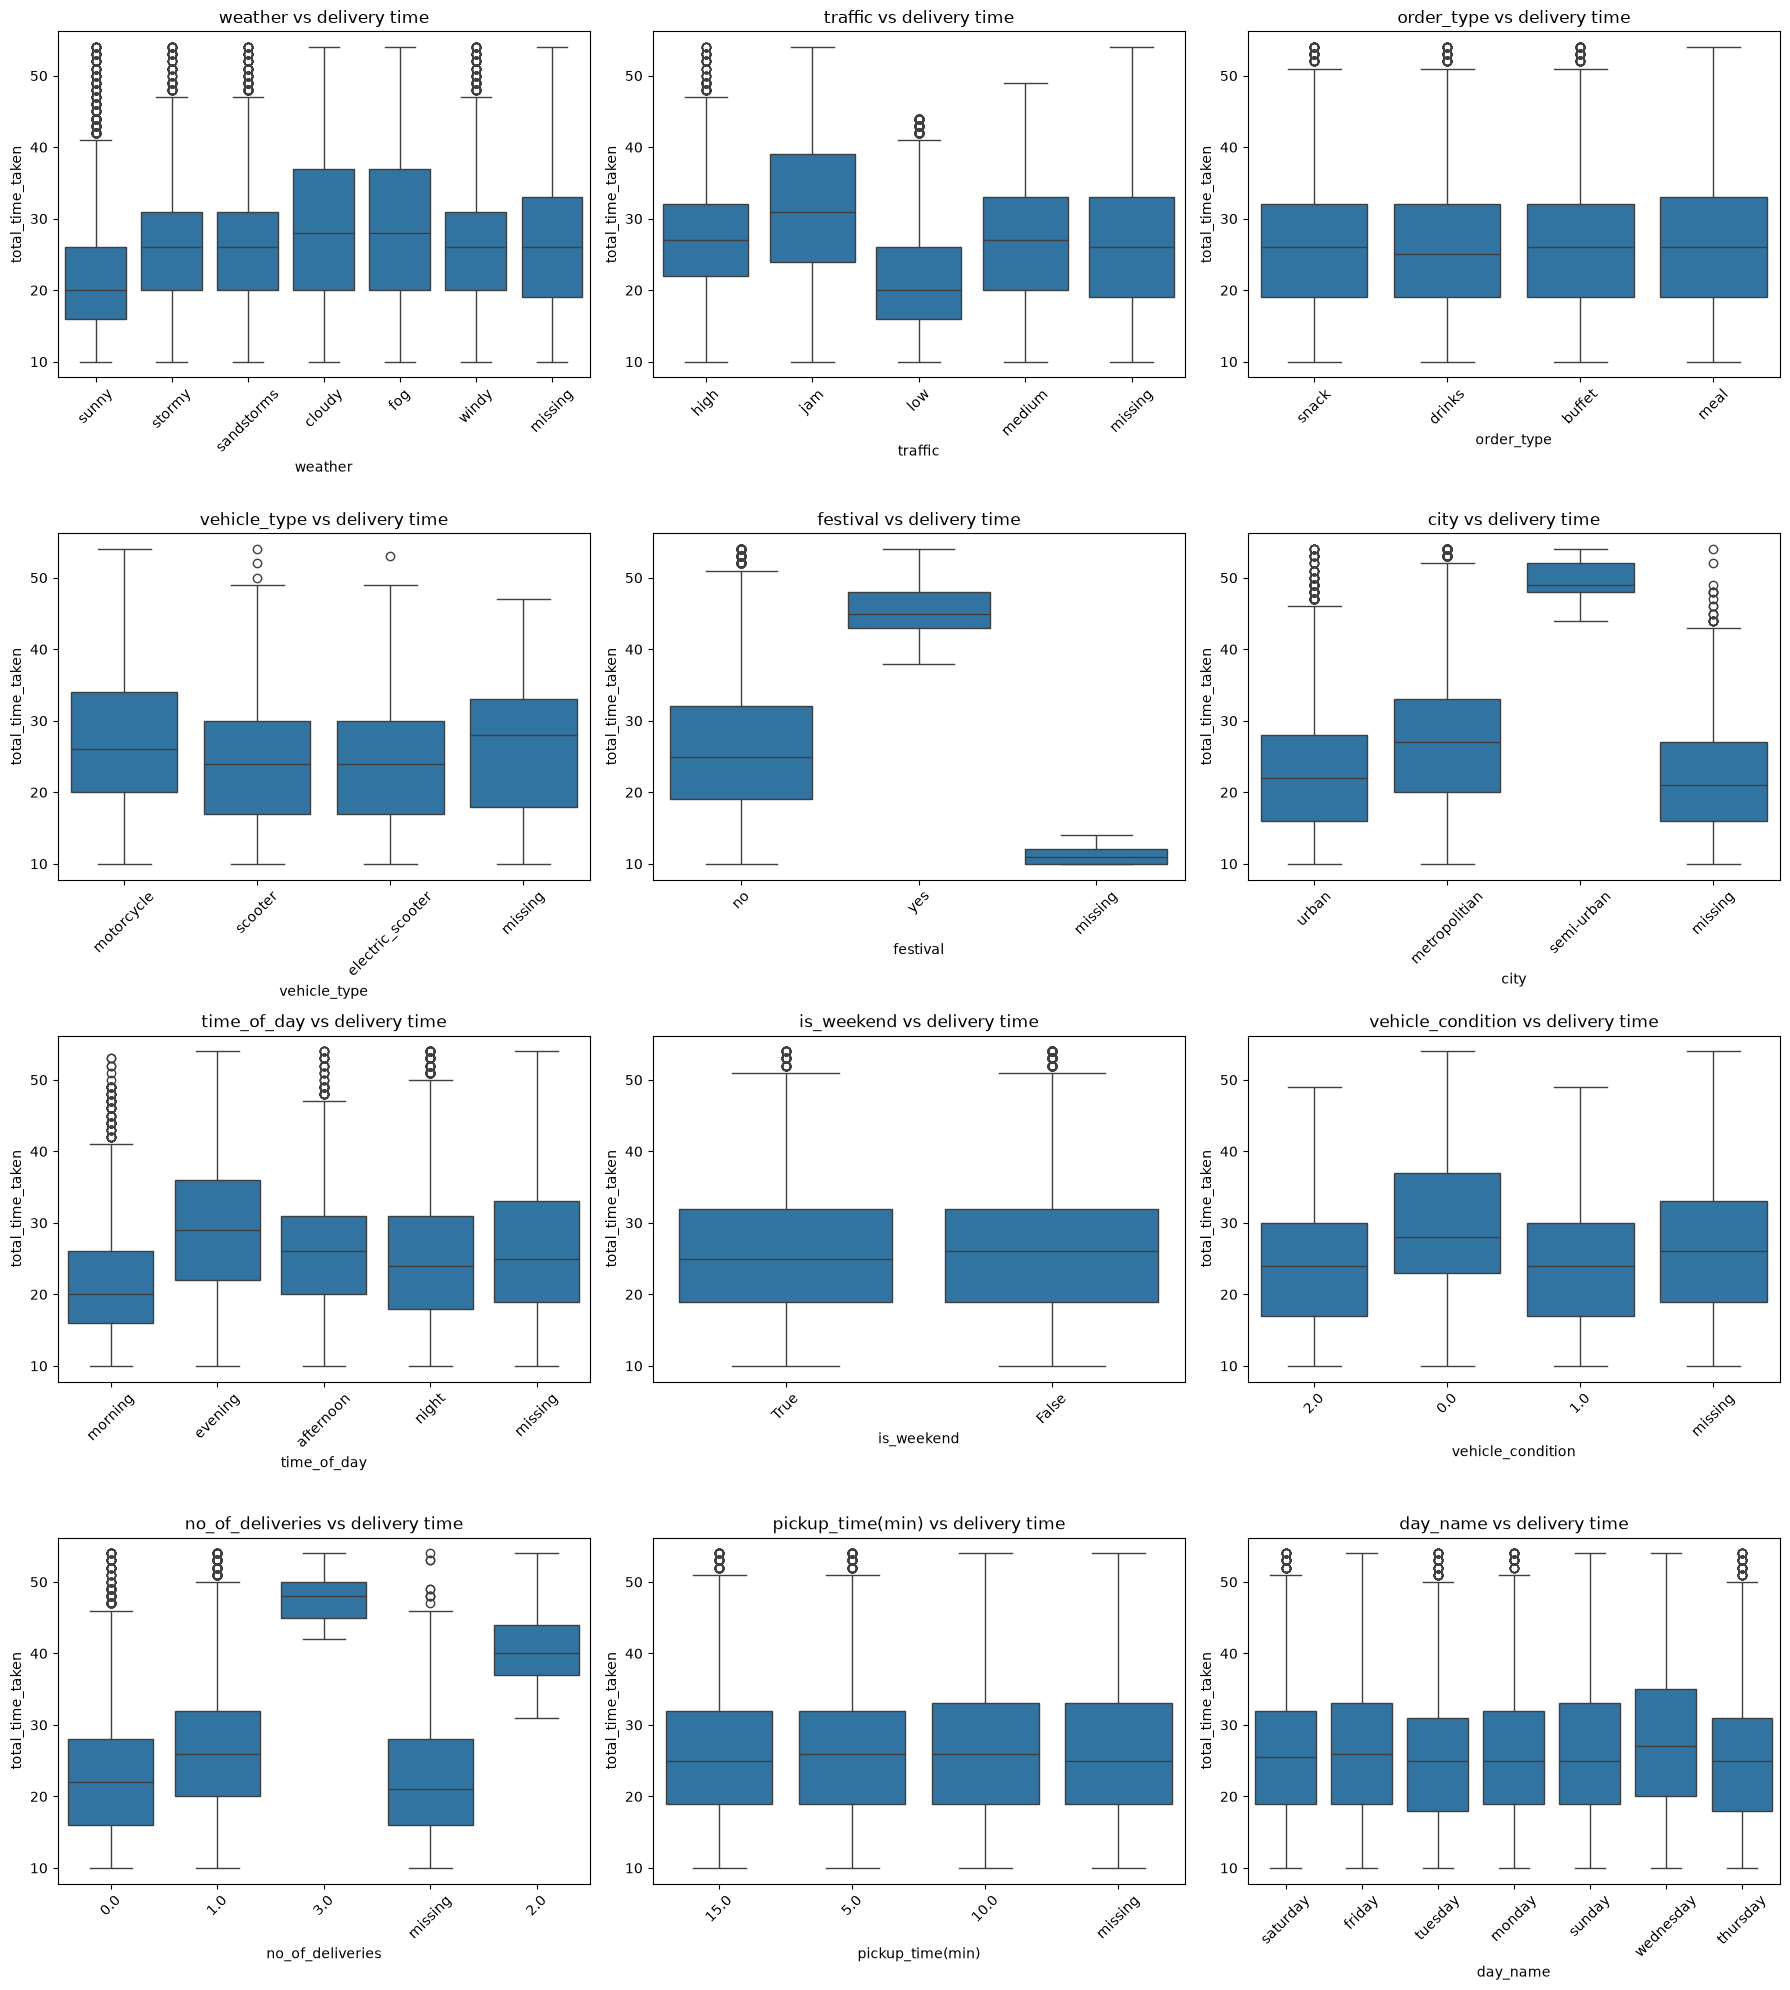

In [9]:
cat_plot_cols = ['weather', 'traffic', 'order_type', 'vehicle_type', 'festival', 'city',
                 'time_of_day', 'is_weekend', 'vehicle_condition', 'no_of_deliveries',
                 'pickup_time(min)', 'day_name']

for col in cat_plot_cols:
    print(df.groupby(with_missing(df[col]))['total_time_taken']
            .agg(['mean', 'median', 'count']).round(1).sort_values('mean'), "\n")

fig, axes = plt.subplots(4, 3, figsize=(18, 20))
axes = axes.flatten()
for i, col in enumerate(cat_plot_cols):
    sns.boxplot(x=with_missing(df[col]), y=df['total_time_taken'], ax=axes[i])
    axes[i].set_title(f'{col} vs delivery time'); axes[i].tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()

traffic      high   jam   low  medium
time_of_day                          
afternoon    63.1   0.0   0.0    36.9
evening       0.0  48.7   0.0    51.3
morning      22.9   0.0  77.1     0.0
night         0.0  35.8  64.2     0.0 

traffic        high   jam   low  medium
city                                   
metropolitian  10.0  33.0  32.3    24.7
semi-urban     10.4  82.8   0.0     6.7
urban           9.4  26.2  40.8    23.5 

festival         no   yes
city                     
metropolitian  97.9   2.1
semi-urban     75.0  25.0
urban          98.9   1.1 

no_of_deliveries   0.0   1.0   2.0   3.0
city                                    
metropolitian     30.0  64.1   5.0   0.8
semi-urban        14.6  47.0  13.4  25.0
urban             36.4  60.7   2.5   0.3 

traffic     high   jam   low  medium
weather                             
cloudy       9.9  31.2  34.6    24.4
fog         10.1  31.7  33.9    24.2
sandstorms   9.4  32.0  34.8    23.8
stormy       9.7  30.6  35.6    24.1
sunny  

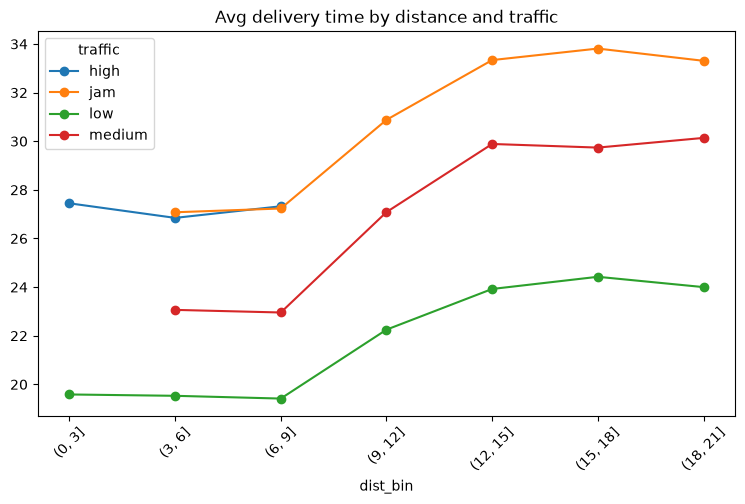

traffic   high   jam   low  medium
dist_bin                          
(0, 3]    24.1   0.0  75.9     0.0
(3, 6]    14.8  20.6  46.8    17.7
(6, 9]    26.0  25.1  16.1    32.8
(9, 12]    0.0  43.0  27.8    29.2
(12, 15]   0.0  43.6  28.2    28.2
(15, 18]   0.0  43.4  29.2    27.5
(18, 21]   0.0  43.6  28.3    28.2
               mean  count
city                      
metropolitian  26.3  30770
semi-urban     49.6     77
urban          22.5   9408


In [10]:
# how the categorical columns overlap
for a, b in [('time_of_day', 'traffic'), ('city', 'traffic'), ('city', 'festival'),
             ('city', 'no_of_deliveries'), ('weather', 'traffic')]:
    print((pd.crosstab(df[a], df[b], normalize='index') * 100).round(1), "\n")

# traffic inside each time of day
print(df.pivot_table(values='total_time_taken', index='time_of_day', columns='traffic', aggfunc='mean').round(1))
print(df.pivot_table(values='total_time_taken', index='time_of_day', columns='traffic', aggfunc='count'))

# distance with traffic held fixed
d = df.dropna(subset=['distance_km']).copy()
d['dist_bin'] = pd.cut(d['distance_km'], bins=[0, 3, 6, 9, 12, 15, 18, 21])
t = d.pivot_table(values='total_time_taken', index='dist_bin', columns='traffic',
                  aggfunc='mean', observed=True)
print(t.round(1))
t.index = t.index.astype(str)
t.plot(marker='o', figsize=(9, 5), title='Avg delivery time by distance and traffic')
plt.xticks(rotation=45); plt.show()
print((pd.crosstab(d['dist_bin'], d['traffic'], normalize='index') * 100).round(1))

# semi-urban without festival and multi-delivery orders
base = df[(df['festival'] == 'no') & (df['no_of_deliveries'].isin([0, 1]))]
print(base.groupby('city')['total_time_taken'].agg(['mean', 'count']).round(1))

total_time_taken: JB=1972.3, p=0, skew=0.49, kurt=-0.31
age: JB=2658.1, p=0, skew=-0.01, kurt=-1.21
rating: JB=71289.2, p=0, skew=-1.79, kurt=5.14
distance_km: JB=2167.4, p=0, skew=0.32, kurt=-0.91
order_hour: JB=8043.7, p=0, skew=-1.02, kurt=0.46


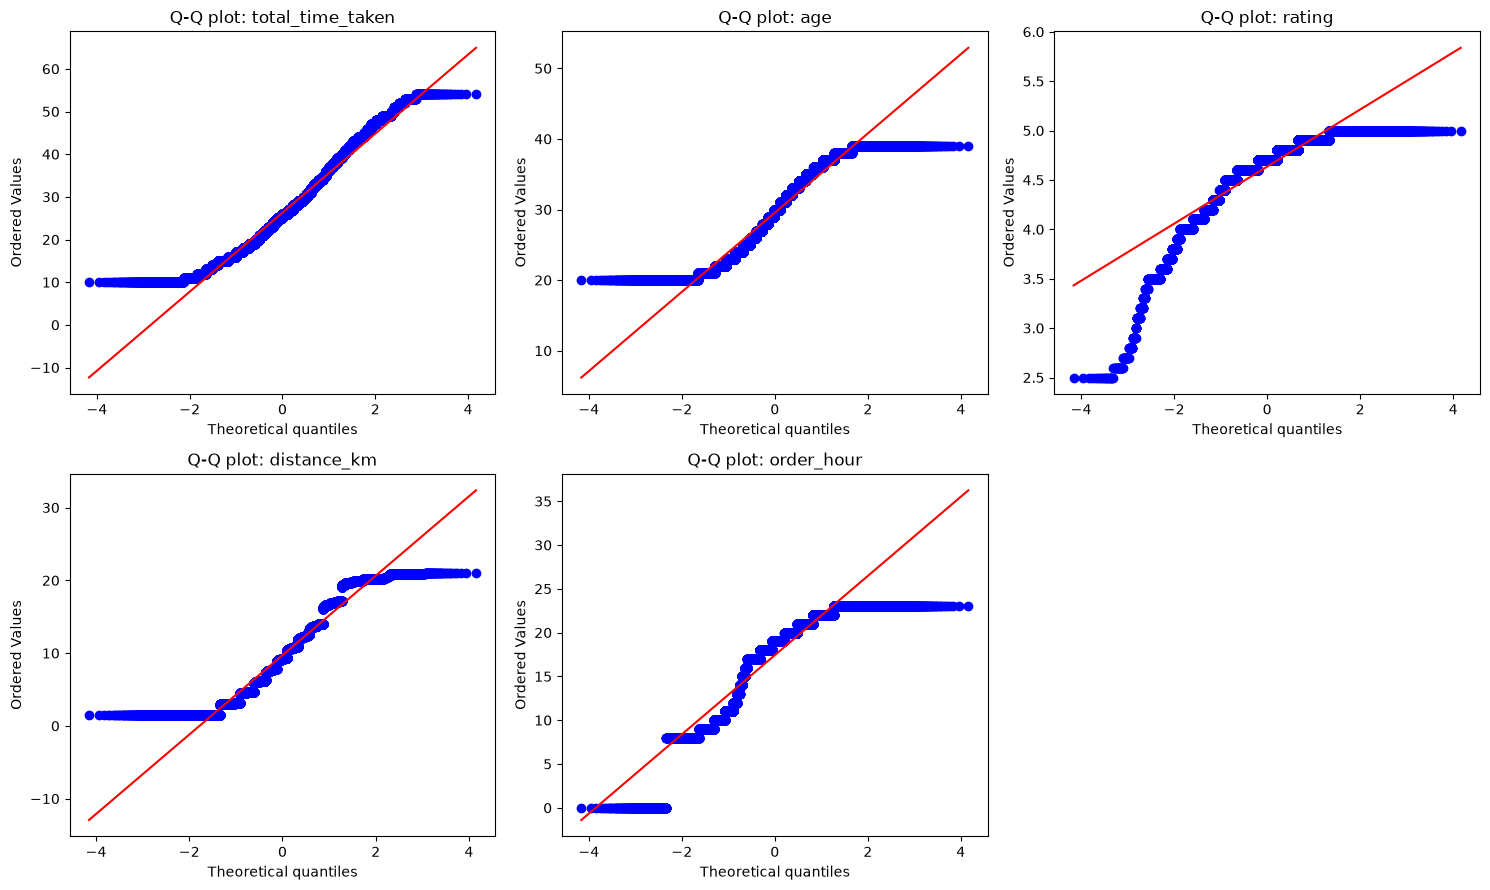

In [11]:
cols = ['total_time_taken', 'age', 'rating', 'distance_km', 'order_hour']
for col in cols:
    data = df[col].dropna()
    stat, p = stats.jarque_bera(data)
    print(f"{col}: JB={stat:.1f}, p={p:.3g}, skew={data.skew():.2f}, kurt={data.kurt():.2f}")

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()
for i, col in enumerate(cols):
    stats.probplot(df[col].dropna(), dist='norm', plot=axes[i]); axes[i].set_title(f'Q-Q plot: {col}')
axes[-1].axis('off')
plt.tight_layout(); plt.show()

In [12]:
y_col = 'total_time_taken'
anova_cols = ['traffic', 'weather', 'city', 'time_of_day', 'vehicle_type', 'vehicle_condition',
              'no_of_deliveries', 'festival', 'order_type', 'day_name', 'is_weekend', 'pickup_time(min)']

rows = []
for col in anova_cols:
    d = df.dropna(subset=[col])
    groups = [g[y_col].values for _, g in d.groupby(col)]
    f, p = stats.f_oneway(*groups)
    grand = d[y_col].mean()
    ssb = sum(len(g) * (g.mean() - grand) ** 2 for g in groups)
    sst = ((d[y_col] - grand) ** 2).sum()
    rows.append([col, round(f, 1), f'{p:.3g}', round(ssb / sst, 4), len(d)])
anova_df = pd.DataFrame(rows, columns=['column', 'F', 'p_value', 'eta_squared', 'rows_used'])
print(anova_df.sort_values('eta_squared', ascending=False).to_string(index=False))

for col in ['traffic', 'weather', 'city', 'no_of_deliveries']:          # Levene (equal spread?)
    d = df.dropna(subset=[col])
    stat, p = stats.levene(*[g[y_col].values for _, g in d.groupby(col)])
    print(f"Levene {col}: stat={stat:.1f}, p={p:.3g}")

for col in anova_cols:                                                   # Kruskal-Wallis (backup)
    d = df.dropna(subset=[col])
    h, p = stats.kruskal(*[g[y_col].values for _, g in d.groupby(col)])
    print(f"Kruskal {col}: H={h:.1f}, p={p:.3g}")

           column      F   p_value  eta_squared  rows_used
 no_of_deliveries 3438.8         0       0.1882      44509
          traffic 3411.3         0       0.1853      44992
      time_of_day 1490.5         0       0.0925      43862
         festival 4177.5         0       0.0845      45274
vehicle_condition 1986.8         0       0.0810      45073
          weather  608.2         0       0.0633      44977
             city 1423.3         0       0.0604      44304
     vehicle_type  630.9 5.29e-271       0.0270      45449
         day_name   59.5   8.9e-74       0.0078      45502
       order_type    1.2     0.304       0.0001      45502
 pickup_time(min)    2.3    0.0993       0.0001      43862
       is_weekend    0.4     0.503       0.0000      45502
Levene traffic: stat=787.2, p=0
Levene weather: stat=267.1, p=1.91e-282
Levene city: stat=83.7, p=5.39e-37
Levene no_of_deliveries: stat=269.6, p=2.12e-173
Kruskal traffic: H=8266.3, p=0
Kruskal weather: H=2948.2, p=0
Kruskal city: H

In [13]:
import pingouin as pg

want = ['A', 'B', 'mean_A', 'mean_B', 'diff', 'pval']
for col in ['traffic', 'no_of_deliveries', 'weather']:
    d = df.dropna(subset=[col])
    gh = pg.pairwise_gameshowell(data=d, dv='total_time_taken', between=col)
    print(col); print(gh[[c for c in want if c in gh.columns]].round(3), "\n")

traffic
      A       B  mean_A  mean_B   diff   pval
0  high     jam  27.240  31.177 -3.937  0.000
1  high     low  27.240  21.267  5.973  0.000
2  high  medium  27.240  26.700  0.540  0.002
3   jam     low  31.177  21.267  9.910  0.000
4   jam  medium  31.177  26.700  4.477  0.000
5   low  medium  21.267  26.700 -5.433  0.000 

no_of_deliveries
     A    B  mean_A  mean_B    diff  pval
0  0.0  1.0  22.875  26.859  -3.984   0.0
1  0.0  2.0  22.875  40.457 -17.582   0.0
2  0.0  3.0  22.875  47.820 -24.945   0.0
3  1.0  2.0  26.859  40.457 -13.598   0.0
4  1.0  3.0  26.859  47.820 -20.961   0.0
5  2.0  3.0  40.457  47.820  -7.363   0.0 

weather
             A           B  mean_A  mean_B   diff   pval
0       cloudy         fog  28.917  28.916  0.001  1.000
1       cloudy  sandstorms  28.917  25.876  3.042  0.000
2       cloudy      stormy  28.917  25.871  3.047  0.000
3       cloudy       sunny  28.917  21.857  7.060  0.000
4       cloudy       windy  28.917  26.119  2.798  0.000
5    

In [14]:
def chi_square(a, b):
    table = pd.crosstab(a, b)
    chi2, p, dof, expected = stats.chi2_contingency(table)
    n = table.values.sum()
    v = np.sqrt(chi2 / (n * (min(table.shape) - 1)))
    return chi2, p, dof, v, expected.min()

# between categorical columns
pairs = [('traffic', 'time_of_day'), ('city', 'traffic'), ('weather', 'traffic'), ('order_type', 'traffic')]
for a, b in pairs:
    chi2, p, dof, v, me = chi_square(df[a], df[b])
    print(f"{a} x {b}: chi2={chi2:.1f}, dof={dof}, p={p:.3g}, V={v:.3f}, min_expected={me:.1f}")

# each column vs fast / medium / slow delivery (helper kept outside df)
speed = pd.cut(df['total_time_taken'], bins=[0, 20, 30, 60], labels=['fast', 'medium', 'slow'])
rows = []
for col in anova_cols:
    chi2, p, dof, v, me = chi_square(df[col], speed)
    rows.append([col, round(chi2, 1), dof, f'{p:.3g}', round(v, 3), round(me, 1)])
print(pd.DataFrame(rows, columns=['column', 'chi2', 'dof', 'p_value', 'cramers_v', 'min_expected'])
      .sort_values('cramers_v', ascending=False).to_string(index=False))

traffic x time_of_day: chi2=47871.0, dof=9, p=0, V=0.603, min_expected=399.0
city x traffic: chi2=497.9, dof=6, p=2.34e-104, V=0.075, min_expected=16.1
weather x traffic: chi2=14.6, dof=15, p=0.48, V=0.010, min_expected=716.5
order_type x traffic: chi2=6.7, dof=9, p=0.673, V=0.007, min_expected=1095.1
           column   chi2  dof   p_value  cramers_v  min_expected
          traffic 7858.5    6         0      0.296        1319.9
 no_of_deliveries 7600.3    6         0      0.292         108.7
         festival 2126.5    2         0      0.217         268.3
      time_of_day 4005.3    6         0      0.214        1207.8
          weather 3608.6   10         0      0.200        2172.7
vehicle_condition 2982.2    4         0      0.182        4477.8
             city 1985.7    4         0      0.150          49.6
     vehicle_type  994.2    4 6.51e-214      0.105        1128.1
         day_name  312.6   12  1.07e-59      0.059        1850.7
 pickup_time(min)    5.3    4     0.259      0.

In [15]:
drop_cols = ['order_type', 'pickup_time(min)', 'is_weekend', 'day_name', 'time_of_day',
             'month_name', 'city_code', 'restaurant_latitude', 'restaurant_longitude',
             'location_latitude', 'location_longitude', 'date', 'time_of_order', 'pickup_time']

model_df = df.drop(columns=drop_cols)
model_df.to_csv(PROCESSED / "model_df.csv", index=False)
print(model_df.shape, model_df.columns.tolist())   # (45502, 12)

(45502, 12) ['age', 'rating', 'weather', 'traffic', 'vehicle_condition', 'vehicle_type', 'no_of_deliveries', 'festival', 'city', 'total_time_taken', 'order_hour', 'distance_km']
